# Final test evaluation


## 1. Purpose and selected model

The Gaussian process was selected for all three targets from training-only grouped cross-validation and validation results. Polynomial Ridge is included to check whether its relative performance carries over to held-out geometries.




In [1]:

import platform
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "prepared").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / "data" / "prepared").is_dir(), "Project root not found"

TEST_INPUTS_PATH = PROJECT_ROOT / "data" / "prepared" / "test_inputs.csv"
TRAIN_PATH = PROJECT_ROOT / "data" / "prepared" / "train.csv"
VALIDATION_PATH = PROJECT_ROOT / "data" / "prepared" / "validation.csv"
FORCES_PATH = PROJECT_ROOT / "data" / "hiliftaeroml" / "force_mom_all.csv"
PREDICTIONS_PATH = PROJECT_ROOT / "results" / "predictions.csv"
VALIDATION_METRICS_PATH = PROJECT_ROOT / "results" / "validation_metrics.csv"
TEST_METRICS_PATH = PROJECT_ROOT / "results" / "test_metrics.csv"
GP_TEST_UNCERTAINTY_PATH = PROJECT_ROOT / "results" / "gp_test_uncertainty_metrics.csv"
GP_MODEL_PATH = PROJECT_ROOT / "results" / "models" / "gaussian_process.joblib"
RIDGE_MODEL_PATH = PROJECT_ROOT / "results" / "models" / "polynomial_ridge.joblib"

MODEL_NAMES = ["gaussian_process", "polynomial_ridge"]
TARGET_NAMES = ["cl", "cd", "cm"]
EXPECTED_AOAS = [4, 6, 8, 10, 12, 14, 16, 18, 20, 22]
EXPECTED_FEATURES = [
    "IB_Flap_Deflection", "OB_Flap_Deflection",
    "IB_Flap_Gap_Multiplier", "OB_Flap_Gap_Multiplier",
    "IB_Slat_Deflection", "OB_Slat_Deflection",
    "IB_Slat_Gap_Multiplier", "OB_Slat_Gap_Multiplier", "AoA",
]
PREDICTION_COLUMNS = [
    "case_id", "GeoID", "AoA", "split", "model", "target",
    "actual", "predicted", "error", "absolute_error", "squared_error",
]
METRIC_COLUMNS = [
    "model", "target", "scope", "AoA", "n_rows",
    "n_geometries", "MAE", "RMSE", "R2",
]
UNCERTAINTY_COLUMNS = [
    "model", "target", "scope", "AoA", "n_rows",
    "coverage_95", "mean_interval_width_95",
]

print(
    f"Python {platform.python_version()} | NumPy {np.__version__} | "
    f"pandas {pd.__version__} | scikit-learn {sklearn.__version__} | "
    f"matplotlib {matplotlib.__version__} | joblib {joblib.__version__}"
)


Python 3.10.20 | NumPy 1.26.4 | pandas 2.3.3 | scikit-learn 1.7.2 | matplotlib 3.10.9 | joblib 1.5.3


## 2. Load saved models and prepared test inputs

In [2]:

bundles = {
    "gaussian_process": joblib.load(GP_MODEL_PATH),
    "polynomial_ridge": joblib.load(RIDGE_MODEL_PATH),
}
test_inputs = pd.read_csv(TEST_INPUTS_PATH, dtype={"GeoID": "string"})
train_ids = pd.read_csv(TRAIN_PATH, usecols=["GeoID"], dtype={"GeoID": "string"})
validation_ids = pd.read_csv(
    VALIDATION_PATH, usecols=["GeoID"], dtype={"GeoID": "string"}
)

assert len(test_inputs) == 360 and test_inputs["GeoID"].nunique() == 36
assert test_inputs["split"].eq("test").all()
assert test_inputs["case_id"].is_unique
assert not test_inputs.duplicated(["GeoID", "AoA"]).any()
assert test_inputs.groupby("GeoID").size().eq(10).all()
assert sorted(test_inputs["AoA"].unique().tolist()) == EXPECTED_AOAS
assert set(TARGET_NAMES).isdisjoint(test_inputs.columns)
assert np.isfinite(test_inputs[EXPECTED_FEATURES].to_numpy()).all()

test_geometries = set(test_inputs["GeoID"])
assert test_geometries.isdisjoint(set(train_ids["GeoID"]))
assert test_geometries.isdisjoint(set(validation_ids["GeoID"]))

for model_name, bundle in bundles.items():
    assert bundle["model_name"] == model_name
    assert bundle["target_names"] == TARGET_NAMES
    assert set(bundle["feature_names"]) == set(EXPECTED_FEATURES)

display(pd.DataFrame({
    "rows": [len(test_inputs)],
    "geometries": [test_inputs["GeoID"].nunique()],
    "AoA values": [test_inputs["AoA"].nunique()],
}))


,rows,geometries,AoA values
0,360,36,10


### Example: inputs and predictions

The first test case shows how to use the final GP model. The saved pipelines apply the fitted preprocessing and return predicted `cl`, `cd`, and `cm`.


In [3]:
example_inputs = test_inputs.loc[:, bundles["gaussian_process"]["feature_names"]].iloc[[0]]
example_predictions = pd.DataFrame({
    "target": TARGET_NAMES,
    "predicted": [
        bundles["gaussian_process"]["pipelines"][target].predict(example_inputs)[0]
        for target in TARGET_NAMES
    ],
})

print(f"Example case: {test_inputs.iloc[0]['case_id']}")
display(example_inputs.T.rename(columns={example_inputs.index[0]: "Input value"}))
display(example_predictions)


Example case: geo_LHC006_AoA_4


,Input value
IB_Flap_Deflection,26.627887
OB_Flap_Deflection,38.463685
IB_Flap_Gap_Multiplier,0.581480
OB_Flap_Gap_Multiplier,0.771078
IB_Slat_Deflection,15.890470
OB_Slat_Deflection,29.694191
IB_Slat_Gap_Multiplier,0.655133
OB_Slat_Gap_Multiplier,0.619757
AoA,4.000000


,target,predicted
0,cl,1.253229
1,cd,0.118419
2,cm,-0.196341



## 3. Generate test predictions



In [3]:

def predict_gp_with_std(pipeline, features):
    scaled = pipeline.named_steps["scaler"].transform(features)
    return pipeline.named_steps["gaussian_process"].predict(scaled, return_std=True)


point_predictions = {model: {} for model in MODEL_NAMES}
gp_standard_deviations = {}

for target in TARGET_NAMES:
    gp_pipeline = bundles["gaussian_process"]["pipelines"][target]
    gp_features = test_inputs.loc[:, bundles["gaussian_process"]["feature_names"]]
    gp_prediction, gp_std = predict_gp_with_std(gp_pipeline, gp_features)
    point_predictions["gaussian_process"][target] = gp_prediction
    gp_standard_deviations[target] = gp_std

    ridge_pipeline = bundles["polynomial_ridge"]["pipelines"][target]
    ridge_features = test_inputs.loc[:, bundles["polynomial_ridge"]["feature_names"]]
    point_predictions["polynomial_ridge"][target] = ridge_pipeline.predict(ridge_features)

for model_name in MODEL_NAMES:
    for target in TARGET_NAMES:
        assert len(point_predictions[model_name][target]) == len(test_inputs)
        assert np.isfinite(point_predictions[model_name][target]).all()
for target in TARGET_NAMES:
    assert np.isfinite(gp_standard_deviations[target]).all()
    assert (gp_standard_deviations[target] >= 0).all()

print("Generated GP and Ridge predictions for 360 test cases before reading targets.")


Generated GP and Ridge predictions for 360 test cases before reading targets.


## 4. Load test targets and calculate metrics

In [4]:

raw_targets = pd.read_csv(
    FORCES_PATH,
    usecols=["GeoID", "AoA", *TARGET_NAMES],
    dtype={"GeoID": "string"},
)
assert not raw_targets.duplicated(["GeoID", "AoA"]).any()

test_keys = test_inputs.loc[:, ["case_id", "GeoID", "AoA"]].copy()
test_keys["_input_order"] = np.arange(len(test_keys))
test_targets = test_keys.merge(
    raw_targets,
    on=["GeoID", "AoA"],
    how="left",
    validate="one_to_one",
    indicator=True,
    sort=False,
)
assert test_targets["_merge"].eq("both").all()
test_targets = (
    test_targets.sort_values("_input_order")
    .drop(columns=["_input_order", "_merge"])
    .reset_index(drop=True)
)
assert test_targets["case_id"].equals(test_inputs["case_id"])
assert np.isfinite(test_targets[TARGET_NAMES].to_numpy()).all()


def make_test_prediction_rows(model_name):
    rows = []
    for target in TARGET_NAMES:
        target_rows = test_inputs.loc[:, ["case_id", "GeoID", "AoA", "split"]].copy()
        target_rows["model"] = model_name
        target_rows["target"] = target
        target_rows["actual"] = test_targets[target].to_numpy()
        target_rows["predicted"] = point_predictions[model_name][target]
        target_rows["error"] = target_rows["predicted"] - target_rows["actual"]
        target_rows["absolute_error"] = target_rows["error"].abs()
        target_rows["squared_error"] = target_rows["error"].pow(2)
        rows.append(target_rows.loc[:, PREDICTION_COLUMNS])
    return pd.concat(rows, ignore_index=True)


new_test_rows = pd.concat(
    [make_test_prediction_rows(model_name) for model_name in MODEL_NAMES],
    ignore_index=True,
)
saved_before = pd.read_csv(
    PREDICTIONS_PATH, dtype={"GeoID": "string"}, float_precision="round_trip"
)
assert list(saved_before.columns) == PREDICTION_COLUMNS
keep_mask = ~(
    saved_before["model"].isin(MODEL_NAMES) & saved_before["split"].eq("test")
)
updated_predictions = pd.concat(
    [saved_before.loc[keep_mask], new_test_rows], ignore_index=True
).loc[:, PREDICTION_COLUMNS]
assert not updated_predictions.duplicated(["case_id", "split", "model", "target"]).any()
updated_predictions.to_csv(PREDICTIONS_PATH, index=False, lineterminator="\n")

saved_predictions = pd.read_csv(
    PREDICTIONS_PATH, dtype={"GeoID": "string"}, float_precision="round_trip"
)
saved_test_rows = saved_predictions.loc[
    saved_predictions["model"].isin(MODEL_NAMES)
    & saved_predictions["split"].eq("test")
].copy()
assert len(saved_test_rows) == 2_160
assert saved_test_rows.groupby(["model", "target"]).size().eq(360).all()


def metric_record(rows, model_name, target, scope, aoa=np.nan):
    return {
        "model": model_name,
        "target": target,
        "scope": scope,
        "AoA": aoa,
        "n_rows": len(rows),
        "n_geometries": rows["GeoID"].nunique(),
        "MAE": mean_absolute_error(rows["actual"], rows["predicted"]),
        "RMSE": root_mean_squared_error(rows["actual"], rows["predicted"]),
        "R2": r2_score(rows["actual"], rows["predicted"]),
    }


def metrics_from_predictions(prediction_rows):
    records = []
    for model_name in MODEL_NAMES:
        for target in TARGET_NAMES:
            target_rows = prediction_rows.loc[
                prediction_rows["model"].eq(model_name)
                & prediction_rows["target"].eq(target)
            ]
            records.append(metric_record(target_rows, model_name, target, "overall"))
            for aoa, aoa_rows in target_rows.groupby("AoA", sort=True):
                records.append(metric_record(aoa_rows, model_name, target, "per_aoa", aoa))
    return pd.DataFrame(records, columns=METRIC_COLUMNS)


test_metrics = metrics_from_predictions(saved_test_rows)
assert len(test_metrics) == 66
assert not test_metrics.duplicated(["model", "target", "scope", "AoA"]).any()
test_metrics.to_csv(TEST_METRICS_PATH, index=False, lineterminator="\n")
saved_test_metrics = pd.read_csv(TEST_METRICS_PATH, float_precision="round_trip")

display(
    saved_test_metrics.loc[saved_test_metrics["scope"].eq("overall")]
    .drop(columns=["scope", "AoA"])
    .reset_index(drop=True)
)


,model,target,n_rows,n_geometries,MAE,RMSE,R2
0,gaussian_process,cl,360,36,0.026258,0.039284,0.979880
1,gaussian_process,cd,360,36,0.006645,0.011692,0.994260
2,gaussian_process,cm,360,36,0.028066,0.046129,0.929528
3,polynomial_ridge,cl,360,36,0.065016,0.082222,0.911859
4,polynomial_ridge,cd,360,36,0.015871,0.021050,0.981397
5,polynomial_ridge,cm,360,36,0.069522,0.089287,0.735973



## 5. Test plots and GP uncertainty

Coverage is the fraction of actual values inside the intervals. Mean width is the average upper bound minus lower bound. Wider intervals can increase coverage while reducing precision. The multiplier 1.96 corresponds to the central 95% of a normal distribution. These are nominal 95% GP prediction intervals, conditional on the fitted model; they are not calibrated bounds or safety guarantees. Because `cl`, `cd`, and `cm` have different response scales, their raw interval widths should be interpreted within each target rather than compared directly across targets.

In [5]:

gp_uncertainty_frames = {}
uncertainty_records = []
for target in TARGET_NAMES:
    rows = test_inputs.loc[:, ["case_id", "GeoID", "AoA"]].copy()
    rows["actual"] = test_targets[target].to_numpy()
    rows["predicted"] = point_predictions["gaussian_process"][target]
    rows["predicted_std"] = gp_standard_deviations[target]
    rows["lower_95"] = rows["predicted"] - 1.96 * rows["predicted_std"]
    rows["upper_95"] = rows["predicted"] + 1.96 * rows["predicted_std"]
    rows["covered_95"] = rows["actual"].between(
        rows["lower_95"], rows["upper_95"], inclusive="both"
    )
    rows["interval_width_95"] = rows["upper_95"] - rows["lower_95"]
    gp_uncertainty_frames[target] = rows

    def add_uncertainty_record(group, scope, aoa=np.nan):
        uncertainty_records.append({
            "model": "gaussian_process",
            "target": target,
            "scope": scope,
            "AoA": aoa,
            "n_rows": len(group),
            "coverage_95": group["covered_95"].mean(),
            "mean_interval_width_95": group["interval_width_95"].mean(),
        })

    add_uncertainty_record(rows, "overall")
    for aoa, aoa_rows in rows.groupby("AoA", sort=True):
        add_uncertainty_record(aoa_rows, "per_aoa", aoa)

gp_test_uncertainty = pd.DataFrame(uncertainty_records, columns=UNCERTAINTY_COLUMNS)
assert len(gp_test_uncertainty) == 33
assert not gp_test_uncertainty.duplicated(["model", "target", "scope", "AoA"]).any()
gp_test_uncertainty.to_csv(
    GP_TEST_UNCERTAINTY_PATH, index=False, lineterminator="\n"
)
saved_gp_test_uncertainty = pd.read_csv(
    GP_TEST_UNCERTAINTY_PATH, float_precision="round_trip"
)

validation_metrics = pd.read_csv(VALIDATION_METRICS_PATH)
validation_test = pd.concat([
    validation_metrics.loc[
        validation_metrics["model"].isin(MODEL_NAMES)
        & validation_metrics["scope"].eq("overall"),
        ["model", "target", "MAE", "RMSE", "R2"],
    ].assign(dataset="validation"),
    saved_test_metrics.loc[
        saved_test_metrics["scope"].eq("overall"),
        ["model", "target", "MAE", "RMSE", "R2"],
    ].assign(dataset="test"),
], ignore_index=True)

display(
    validation_test.pivot(index=["target", "model"], columns="dataset", values=["MAE", "RMSE", "R2"])
)
display(
    saved_gp_test_uncertainty.loc[
        saved_gp_test_uncertainty["scope"].eq("overall")
    ].reset_index(drop=True)
)


MAE                 RMSE                   R2  \
dataset                      test validation      test validation      test   
target model                                                                  
cd     gaussian_process  0.006645   0.004977  0.011692   0.010041  0.994260   
       polynomial_ridge  0.015871   0.015438  0.021050   0.020679  0.981397   
cl     gaussian_process  0.026258   0.020616  0.039284   0.037197  0.979880   
       polynomial_ridge  0.065016   0.063269  0.082222   0.081532  0.911859   
cm     gaussian_process  0.028066   0.024907  0.046129   0.043410  0.929528   
       polynomial_ridge  0.069522   0.053314  0.089287   0.073929  0.735973   

                                    
dataset                 validation  
target model                        
cd     gaussian_process   0.994114  
       polynomial_ridge   0.975039  
cl     gaussian_process   0.987627  
       polynomial_ridge   0.940554  
cm     gaussian_process   0.957790  
       polynomial_ridge   0.877576

,model,target,scope,AoA,n_rows,coverage_95,mean_interval_width_95
0,gaussian_process,cl,overall,NaN,360,0.900000,0.127675
1,gaussian_process,cd,overall,NaN,360,0.872222,0.034667
2,gaussian_process,cm,overall,NaN,360,0.919444,0.156408


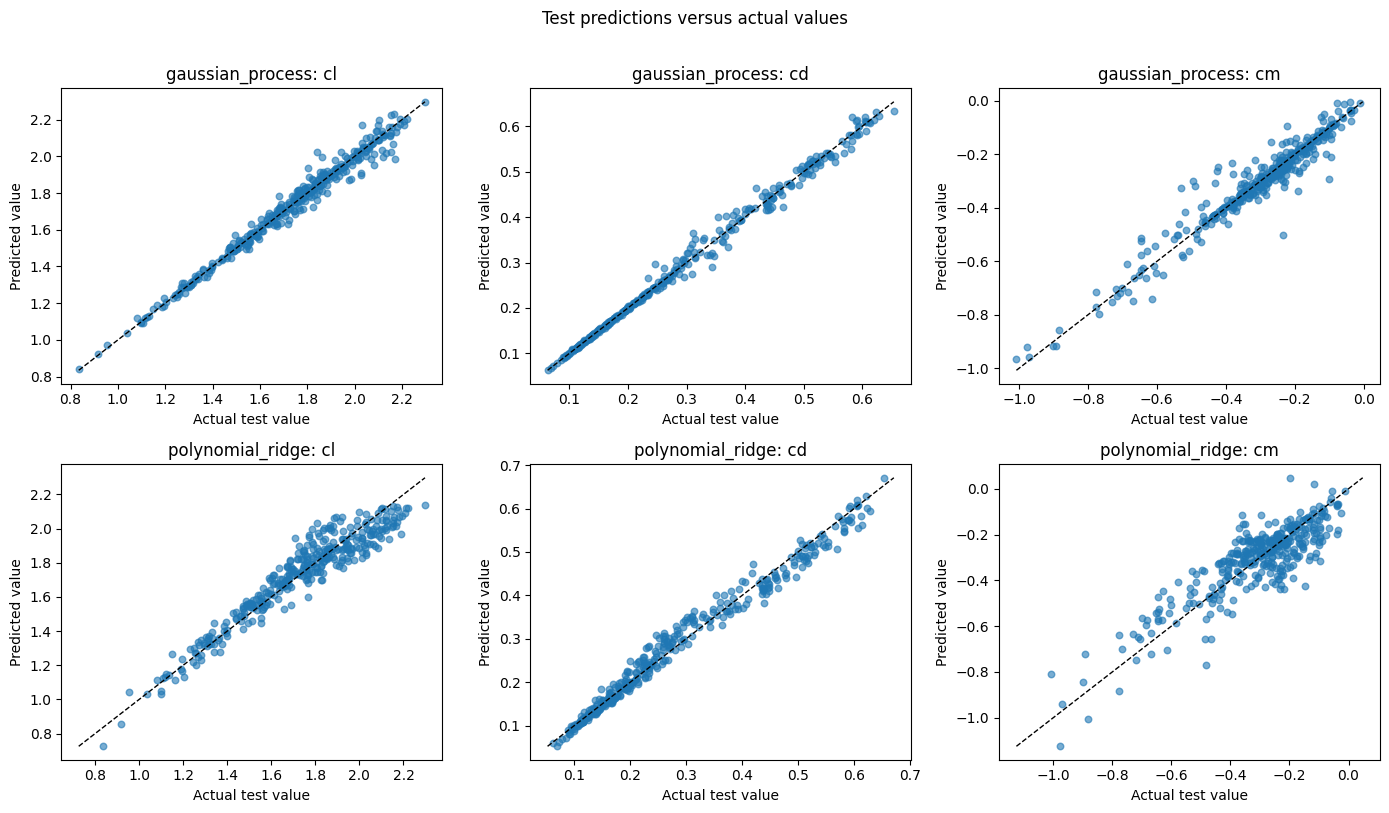

In [6]:

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for row_index, model_name in enumerate(MODEL_NAMES):
    for column_index, target in enumerate(TARGET_NAMES):
        axis = axes[row_index, column_index]
        rows = saved_test_rows.loc[
            saved_test_rows["model"].eq(model_name)
            & saved_test_rows["target"].eq(target)
        ]
        axis.scatter(rows["actual"], rows["predicted"], alpha=0.6, s=22)
        limits = [
            min(rows["actual"].min(), rows["predicted"].min()),
            max(rows["actual"].max(), rows["predicted"].max()),
        ]
        axis.plot(limits, limits, color="black", linestyle="--", linewidth=1)
        axis.set_title(f"{model_name}: {target}")
        axis.set_xlabel("Actual test value")
        axis.set_ylabel("Predicted value")
fig.suptitle("Test predictions versus actual values", y=1.01)
fig.tight_layout()
plt.show()


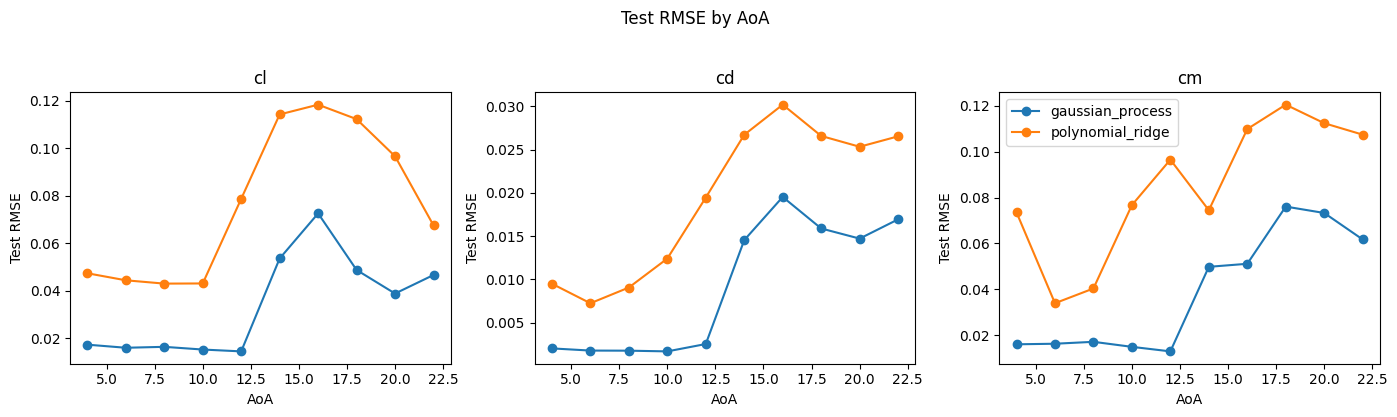

In [7]:

per_aoa_test = saved_test_metrics.loc[saved_test_metrics["scope"].eq("per_aoa")]
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
for axis, target in zip(axes, TARGET_NAMES):
    for model_name in MODEL_NAMES:
        rows = per_aoa_test.loc[
            per_aoa_test["target"].eq(target)
            & per_aoa_test["model"].eq(model_name)
        ].sort_values("AoA")
        axis.plot(rows["AoA"], rows["RMSE"], marker="o", label=model_name)
    axis.set_title(target)
    axis.set_xlabel("AoA")
    axis.set_ylabel("Test RMSE")
axes[-1].legend()
fig.suptitle("Test RMSE by AoA", y=1.03)
fig.tight_layout()
plt.show()


In [2]:
# Reload the saved GP for prediction-only uncertainty plots.
plot_bundle = joblib.load(GP_MODEL_PATH)
plot_test_inputs = pd.read_csv(TEST_INPUTS_PATH, dtype={"GeoID": "string"})
plot_saved_predictions = pd.read_csv(
    PREDICTIONS_PATH, dtype={"GeoID": "string"}, float_precision="round_trip"
)
plot_saved_uncertainty = pd.read_csv(
    GP_TEST_UNCERTAINTY_PATH, float_precision="round_trip"
)
plot_uncertainty = {}

for target in TARGET_NAMES:
    saved_rows = plot_saved_predictions.loc[
        plot_saved_predictions["model"].eq("gaussian_process")
        & plot_saved_predictions["split"].eq("test")
        & plot_saved_predictions["target"].eq(target),
        ["case_id", "GeoID", "AoA", "actual", "predicted"],
    ]
    rows = plot_test_inputs.loc[
        :, [
            "case_id", "GeoID", *plot_bundle["feature_names"]
        ]
    ].merge(
        saved_rows,
        on=["case_id", "GeoID", "AoA"],
        how="left",
        validate="one_to_one",
    )
    pipeline = plot_bundle["pipelines"][target]
    features = rows.loc[:, plot_bundle["feature_names"]]
    scaled_features = pipeline.named_steps["scaler"].transform(features)
    predicted, predicted_std = pipeline.named_steps["gaussian_process"].predict(
        scaled_features, return_std=True
    )
    assert np.allclose(predicted, rows["predicted"])

    rows["predicted_std"] = predicted_std
    rows["lower_95"] = rows["predicted"] - 1.96 * rows["predicted_std"]
    rows["upper_95"] = rows["predicted"] + 1.96 * rows["predicted_std"]
    rows["covered_95"] = rows["actual"].between(
        rows["lower_95"], rows["upper_95"], inclusive="both"
    )
    rows["interval_width_95"] = rows["upper_95"] - rows["lower_95"]
    rows = rows.sort_values(["AoA", "GeoID"], kind="stable").reset_index(drop=True)
    assert len(rows) == 360 and rows["case_id"].is_unique
    plot_uncertainty[target] = rows

    saved_target = plot_saved_uncertainty.loc[
        plot_saved_uncertainty["model"].eq("gaussian_process")
        & plot_saved_uncertainty["target"].eq(target)
    ]
    saved_overall = saved_target.loc[saved_target["scope"].eq("overall")].iloc[0]
    assert np.isclose(rows["covered_95"].mean(), saved_overall["coverage_95"])
    assert np.isclose(
        rows["interval_width_95"].mean(),
        saved_overall["mean_interval_width_95"],
    )
    plotted_by_aoa = rows.groupby("AoA").agg(
        coverage_95=("covered_95", "mean"),
        mean_interval_width_95=("interval_width_95", "mean"),
    )
    saved_by_aoa = saved_target.loc[saved_target["scope"].eq("per_aoa")].set_index("AoA")
    assert np.allclose(plotted_by_aoa["coverage_95"], saved_by_aoa["coverage_95"])
    assert np.allclose(
        plotted_by_aoa["mean_interval_width_95"],
        saved_by_aoa["mean_interval_width_95"],
    )


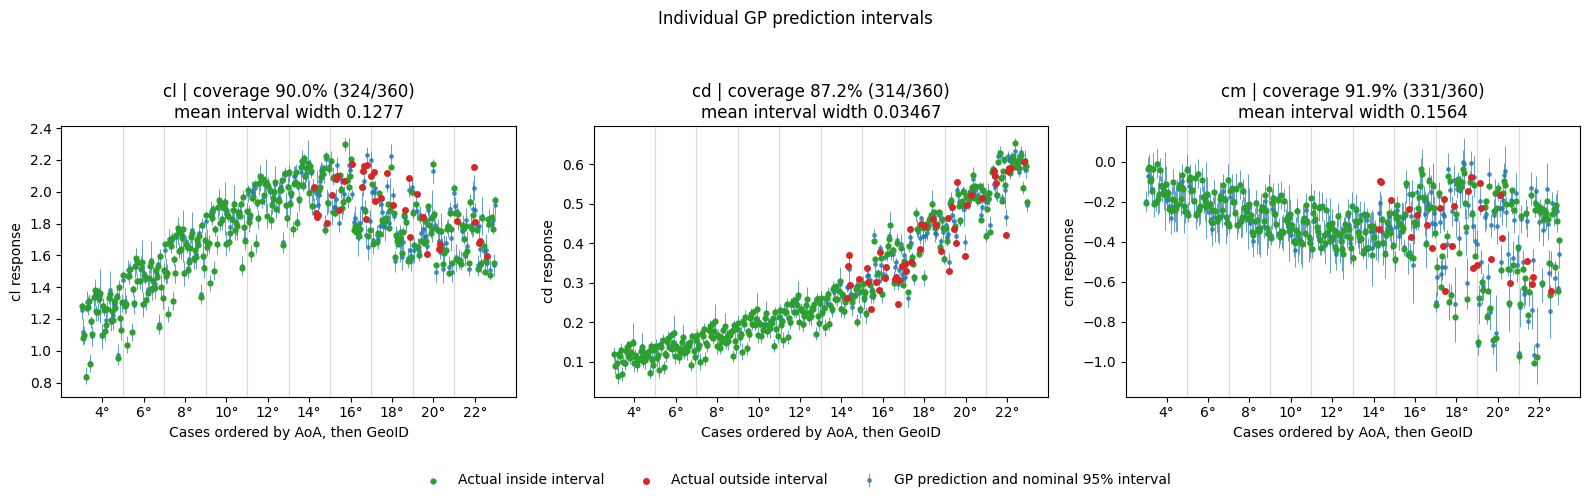

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for axis, target in zip(axes, TARGET_NAMES):
    rows = plot_uncertainty[target]
    positions = np.arange(len(rows))
    covered = rows["covered_95"].to_numpy()
    axis.errorbar(
        positions,
        rows["predicted"],
        yerr=1.96 * rows["predicted_std"],
        fmt="o",
        markersize=2.5,
        color="tab:blue",
        ecolor="tab:blue",
        elinewidth=0.7,
        alpha=0.7,
        capsize=0,
        label="GP prediction and nominal 95% interval",
        zorder=1,
    )
    axis.scatter(
        positions[covered], rows.loc[covered, "actual"],
        s=12, color="tab:green", label="Actual inside interval", zorder=2,
    )
    axis.scatter(
        positions[~covered], rows.loc[~covered, "actual"],
        s=16, color="tab:red", label="Actual outside interval", zorder=3,
    )

    groups = rows.groupby("AoA", sort=True).indices
    centers = [np.mean(indexes) for indexes in groups.values()]
    boundaries = [max(indexes) + 0.5 for indexes in list(groups.values())[:-1]]
    for boundary in boundaries:
        axis.axvline(boundary, color="0.85", linewidth=0.8, zorder=0)
    axis.set_xticks(centers, [f"{aoa:g}°" for aoa in groups])
    axis.set_xlabel("Cases ordered by AoA, then GeoID")
    axis.set_ylabel(f"{target} response")

    covered_count = int(covered.sum())
    total_count = len(rows)
    coverage = covered_count / total_count
    mean_width = rows["interval_width_95"].mean()
    axis.set_title(
        f"{target} | coverage {coverage:.1%} ({covered_count}/{total_count})\n"
        f"mean interval width {mean_width:.4g}"
    )

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.01),
    ncol=3, frameon=False,
)
fig.suptitle("Individual GP prediction intervals", y=0.99)
fig.tight_layout(rect=[0, 0.10, 1, 0.94])
plt.show()


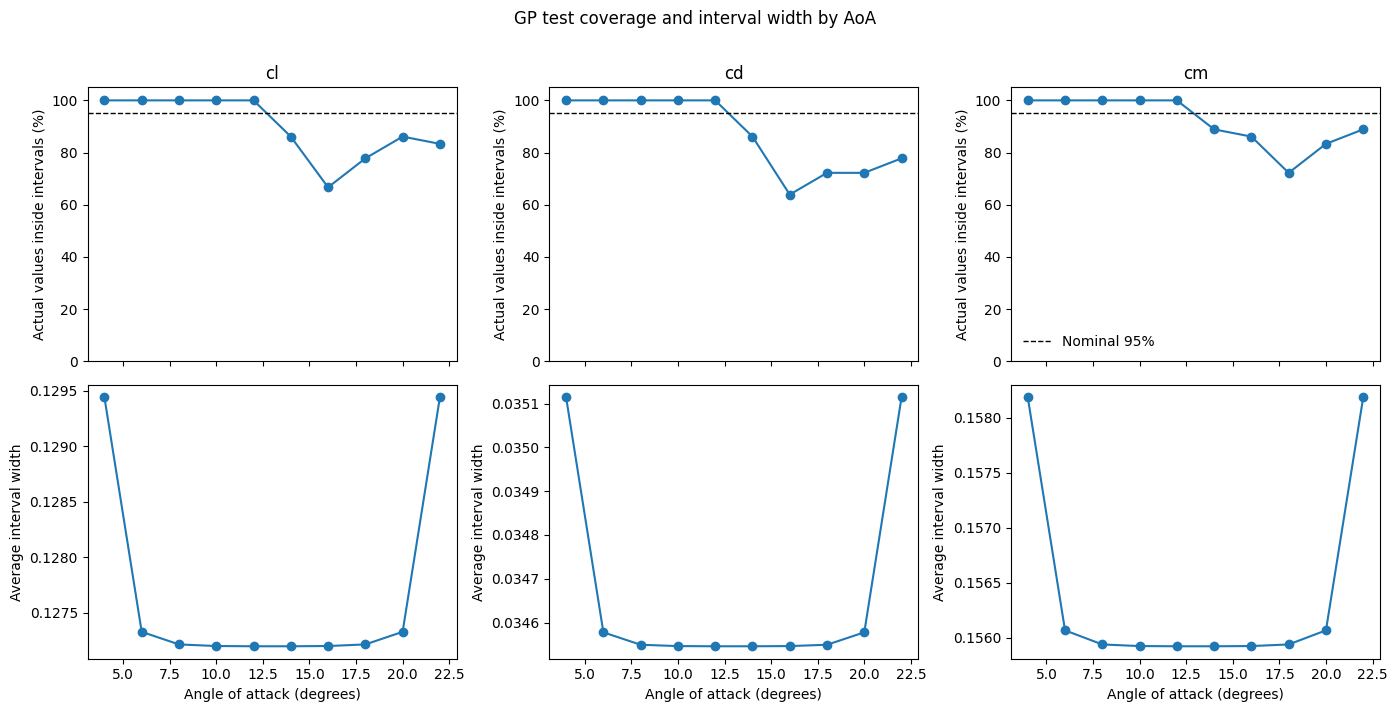

In [4]:
coverage_by_aoa = plot_saved_uncertainty.loc[
    plot_saved_uncertainty["model"].eq("gaussian_process")
    & plot_saved_uncertainty["scope"].eq("per_aoa")
]

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex="col")
for column, target in enumerate(TARGET_NAMES):
    rows = coverage_by_aoa.loc[
        coverage_by_aoa["target"].eq(target)
    ].sort_values("AoA")
    axes[0, column].plot(rows["AoA"], 100 * rows["coverage_95"], marker="o")
    axes[0, column].axhline(
        95, color="black", linestyle="--", linewidth=1, label="Nominal 95%"
    )
    axes[0, column].set_ylim(0, 105)
    axes[0, column].set_title(target)
    axes[0, column].set_ylabel("Actual values inside intervals (%)")
    axes[1, column].plot(
        rows["AoA"], rows["mean_interval_width_95"], marker="o"
    )
    axes[1, column].set_xlabel("Angle of attack (degrees)")
    axes[1, column].set_ylabel("Average interval width")
axes[0, -1].legend(frameon=False)
fig.suptitle("GP test coverage and interval width by AoA", y=1.01)
fig.tight_layout()
plt.show()


## 6. Short conclusion and saved results

In [ ]:

overall_validation = validation_test.loc[validation_test["dataset"].eq("validation")].set_index(
    ["model", "target"]
)
overall_test = validation_test.loc[validation_test["dataset"].eq("test")].set_index(
    ["model", "target"]
)

for model_name in MODEL_NAMES:
    for target in TARGET_NAMES:
        validation_rmse = overall_validation.loc[(model_name, target), "RMSE"]
        test_rmse = overall_test.loc[(model_name, target), "RMSE"]
        direction = "higher" if test_rmse > validation_rmse else "lower"
        hardest_aoa = per_aoa_test.loc[
            per_aoa_test["model"].eq(model_name)
            & per_aoa_test["target"].eq(target)
        ].sort_values("RMSE", ascending=False).iloc[0]["AoA"]
        print(
            f"{model_name}, {target}: test RMSE={test_rmse:.6f} "
            f"({direction} than validation {validation_rmse:.6f}); "
            f"largest test RMSE at AoA={hardest_aoa:g}."
        )

for target in TARGET_NAMES:
    coverage = saved_gp_test_uncertainty.loc[
        saved_gp_test_uncertainty["scope"].eq("overall")
        & saved_gp_test_uncertainty["target"].eq(target),
        "coverage_95",
    ].iloc[0]
    print(f"GP {target}: empirical 95% interval coverage={coverage:.3f}.")

recomputed_metrics = metrics_from_predictions(saved_test_rows)
pd.testing.assert_frame_equal(
    saved_test_metrics.sort_values(["model", "target", "scope", "AoA"]).reset_index(drop=True),
    recomputed_metrics.sort_values(["model", "target", "scope", "AoA"]).reset_index(drop=True),
    check_dtype=False, rtol=1e-12, atol=1e-12,
)
for model_name in MODEL_NAMES:
    for target in TARGET_NAMES:
        recorded = (
            saved_test_rows.loc[
                saved_test_rows["model"].eq(model_name)
                & saved_test_rows["target"].eq(target)
            ]
            .set_index("case_id")
            .reindex(test_inputs["case_id"])["predicted"]
            .to_numpy()
        )
        assert np.allclose(recorded, point_predictions[model_name][target])

assert len(saved_test_rows) == 2_160
assert len(saved_test_metrics) == 66
assert len(saved_gp_test_uncertainty) == 33
assert not saved_predictions.duplicated(["case_id", "split", "model", "target"]).any()
assert not saved_test_metrics.duplicated(["model", "target", "scope", "AoA"]).any()
assert not saved_gp_test_uncertainty.duplicated(["model", "target", "scope", "AoA"]).any()



gaussian_process, cl: test RMSE=0.039284 (higher than validation 0.037197); largest test RMSE at AoA=16.
gaussian_process, cd: test RMSE=0.011692 (higher than validation 0.010041); largest test RMSE at AoA=16.
gaussian_process, cm: test RMSE=0.046129 (higher than validation 0.043410); largest test RMSE at AoA=18.
polynomial_ridge, cl: test RMSE=0.082222 (higher than validation 0.081532); largest test RMSE at AoA=16.
polynomial_ridge, cd: test RMSE=0.021050 (higher than validation 0.020679); largest test RMSE at AoA=16.
polynomial_ridge, cm: test RMSE=0.089287 (higher than validation 0.073929); largest test RMSE at AoA=18.
GP cl: empirical 95% interval coverage=0.900.
GP cd: empirical 95% interval coverage=0.872.
GP cm: empirical 95% interval coverage=0.919.
The pre-test GP selection is unchanged; Ridge remains the comparison model.
Saved prediction, metric, uncertainty, uniqueness, and model-reload checks passed.



Saved results:

- `results/predictions.csv` 
- `results/test_metrics.csv` — overall and per-AoA test metrics
- `results/gp_test_uncertainty_metrics.csv` — GP test coverage and interval width
